# Telco Customer Churn Prediction

**Goal:** Build a predictive ML pipeline that identifies IBM Telco customers likely to churn, enabling proactive retention strategies.

**Dataset:** IBM Telco Customer Churn — 7,043 rows × 21 features. Target variable: `Churn` (Yes/No).

**Pipeline Stages:**
1. Data Loading & Initial Inspection
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Model Training
5. Model Evaluation
6. Report Generation

---
## Stage 1: Data Loading & Initial Inspection

In [57]:
# ── Imports & global settings ──────────────────────────────────────────────
# All libraries used across the full notebook are imported here so every
# downstream stage has access without additional import cells.

import warnings
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

# Reproducibility seed — applied globally so every random operation is fixed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Suppress noisy convergence / future warnings during model training
warnings.filterwarnings('ignore')

# Consistent plot style across all figures
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

print('All imports successful. RANDOM_STATE =', RANDOM_STATE)

All imports successful. RANDOM_STATE = 42


In [58]:
# ── Dataset loading — URL-first with local fallback ─────────────────────────
# The notebook first attempts to download the IBM Telco Customer Churn CSV
# directly from the official IBM GitHub repository. If that fails (e.g. no
# internet connection), it falls back to a local file in the same directory.

DATASET_URL = (
    'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d'
    '/master/data/Telco-Customer-Churn.csv'
)
LOCAL_PATH = './Telco-Customer-Churn.csv'

try:
    df = pd.read_csv(DATASET_URL)
    print(f'Dataset loaded from URL: {DATASET_URL}')
except Exception as e:
    print(f'URL download failed ({e}). Falling back to local file: {LOCAL_PATH}')
    df = pd.read_csv(LOCAL_PATH)
    print(f'Dataset loaded from local file: {LOCAL_PATH}')

print(f'\nLoaded successfully — shape: {df.shape}')

Dataset loaded from URL: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

Loaded successfully — shape: (7043, 21)


In [59]:
# ── Fix TotalCharges: whitespace strings → NaN → float ──────────────────────
# In this dataset, 11 rows have a single space (' ') in the TotalCharges
# column instead of a numeric value. pd.read_csv loads the column as object
# dtype. We coerce to numeric so those rows become NaN (handled in Stage 3).

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print('TotalCharges dtype after conversion:', df['TotalCharges'].dtype)
print('TotalCharges NaN count:', df['TotalCharges'].isna().sum())

TotalCharges dtype after conversion: float64
TotalCharges NaN count: 11


In [60]:
# ── Initial inspection ────────────────────────────────────────────────────────
# Print dataset dimensions, column data types, the first five rows, and a
# summary of null values so we know exactly what we're working with before EDA.

print('=' * 60)
print('SHAPE')
print('=' * 60)
print(f'{df.shape[0]:,} rows  ×  {df.shape[1]} columns')

print('\n' + '=' * 60)
print('COLUMN DATA TYPES')
print('=' * 60)
print(df.dtypes.to_string())

print('\n' + '=' * 60)
print('FIRST 5 ROWS')
print('=' * 60)
df.head()

SHAPE
7,043 rows  ×  21 columns

COLUMN DATA TYPES
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str

FIRST 5 ROWS


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [61]:
# ── Null value summary & target distribution ─────────────────────────────────
# Show which columns contain missing values and the overall count, then print
# the distribution of the target variable Churn so class imbalance is visible.

print('=' * 60)
print('NULL VALUE SUMMARY (columns with nulls only)')
print('=' * 60)
null_counts = df.isnull().sum()
null_counts = null_counts[null_counts > 0]
if null_counts.empty:
    print('No null values detected.')
else:
    print(null_counts.to_string())

print('\n' + '=' * 60)
print('TARGET VARIABLE DISTRIBUTION  (Churn)')
print('=' * 60)
churn_counts = df['Churn'].value_counts()
churn_pct    = df['Churn'].value_counts(normalize=True) * 100
churn_summary = pd.DataFrame({'Count': churn_counts, 'Percent (%)': churn_pct.round(1)})
print(churn_summary.to_string())

NULL VALUE SUMMARY (columns with nulls only)
TotalCharges    11

TARGET VARIABLE DISTRIBUTION  (Churn)
       Count  Percent (%)
Churn                    
No      5174         73.5
Yes     1869         26.5


**Stage 1 observations:**
- The dataset has 7,043 rows and 21 columns.
- `TotalCharges` contained whitespace entries that have been coerced to `NaN` — these will be imputed in Stage 3.
- `Churn` is imbalanced: approximately **26% Yes / 74% No**. This makes ROC-AUC and F1-Score more informative than raw accuracy for model comparison.

---
## Stage 2: Exploratory Data Analysis (EDA)

In [62]:
# ── Create figures/ directory for saving all plot outputs ────────────────────
# All plots are saved here as .png files AND rendered inline via plt.show().
# os.makedirs with exist_ok=True is safe to re-run without errors.

os.makedirs('figures', exist_ok=True)
print('figures/ directory ready.')

figures/ directory ready.


In [63]:
# ── Summary statistics ────────────────────────────────────────────────────────
# Numeric summary (count, mean, std, min/max, quartiles) for continuous columns.
# Categorical summary (count, unique, top, freq) for object-type columns.

print('=' * 70)
print('NUMERIC SUMMARY STATISTICS')
print('=' * 70)
display(df.describe().round(2))

print('\n' + '=' * 70)
print('CATEGORICAL SUMMARY STATISTICS')
print('=' * 70)
display(df.describe(include='object'))

NUMERIC SUMMARY STATISTICS


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00,7032.00
mean,0.16,32.37,64.76,2283.30
std,0.37,24.56,30.09,2266.77
min,0.00,0.00,18.25,18.80
25%,0.00,9.00,35.50,401.45
50%,0.00,29.00,70.35,1397.48
75%,0.00,55.00,89.85,3794.74
max,1.00,72.00,118.75,8684.80



CATEGORICAL SUMMARY STATISTICS


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


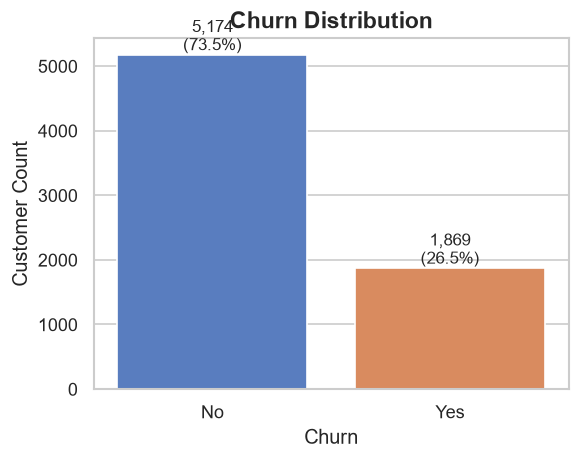

Churn value counts:
 Churn
No     5174
Yes    1869


In [64]:
# ── Churn distribution countplot ─────────────────────────────────────────────
# Visualises the class imbalance clearly. Annotated with exact counts so the
# ~26% churn rate is immediately visible.

fig, ax = plt.subplots(figsize=(5, 4))
order = ['No', 'Yes']
sns.countplot(data=df, x='Churn', order=order, palette='muted', ax=ax)
ax.set_title('Churn Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Churn', fontsize=12)
ax.set_ylabel('Customer Count', fontsize=12)

# Annotate bars with count and percentage
total = len(df)
for p in ax.patches:
    count = int(p.get_height())
    pct   = count / total * 100
    ax.annotate(f'{count:,}\n({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('figures/eda_churn_distribution.png', bbox_inches='tight')
plt.show()
print('Churn value counts:\n', df['Churn'].value_counts().to_string())

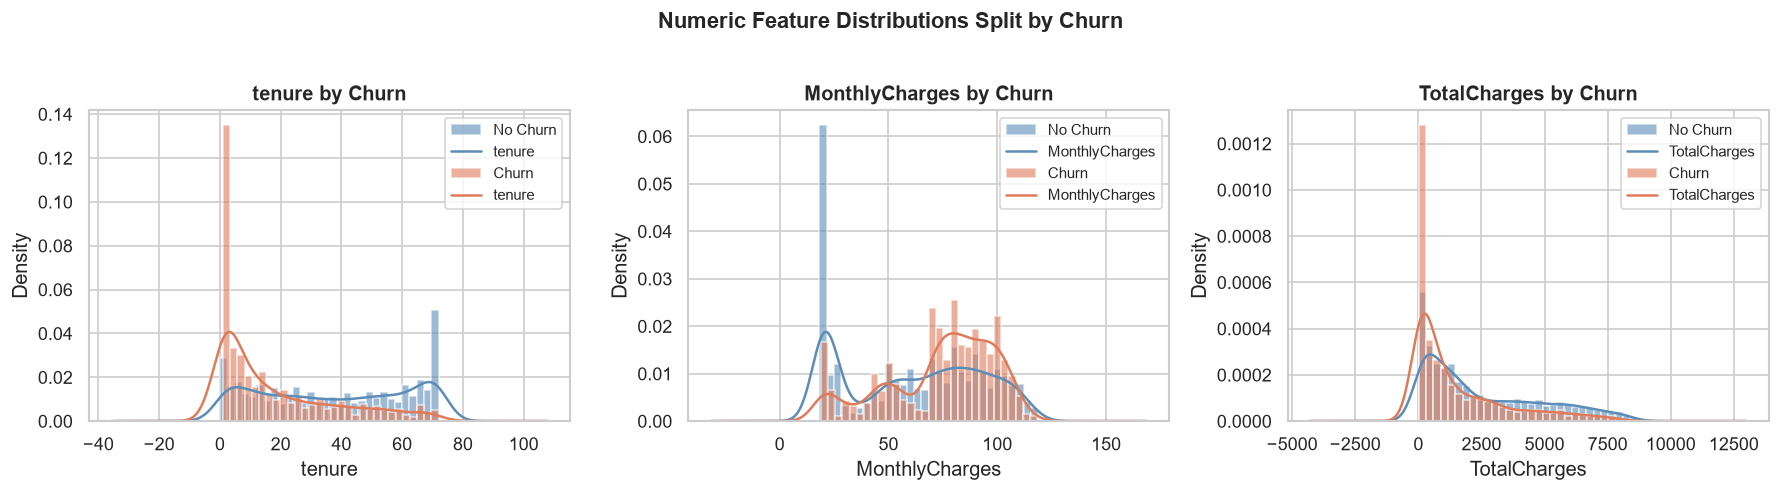

In [65]:
# ── Numeric feature distributions by Churn ───────────────────────────────────
# Histograms with KDE overlays for tenure, MonthlyCharges, and TotalCharges,
# split by Churn class. Churned customers tend to be newer (lower tenure) and
# pay higher monthly charges.

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric_cols):
    for churn_val, label, color in [('No', 'No Churn', '#5B8DB8'), ('Yes', 'Churn', '#E07B5A')]:
        subset = df[df['Churn'] == churn_val][col].dropna()
        ax.hist(subset, bins=30, alpha=0.6, label=label, color=color, density=True)
        subset.plot.kde(ax=ax, color=color, linewidth=1.5)
    ax.set_title(f'{col} by Churn', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Density')
    ax.legend(fontsize=9)

plt.suptitle('Numeric Feature Distributions Split by Churn', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/eda_numeric_distributions.png', bbox_inches='tight')
plt.show()

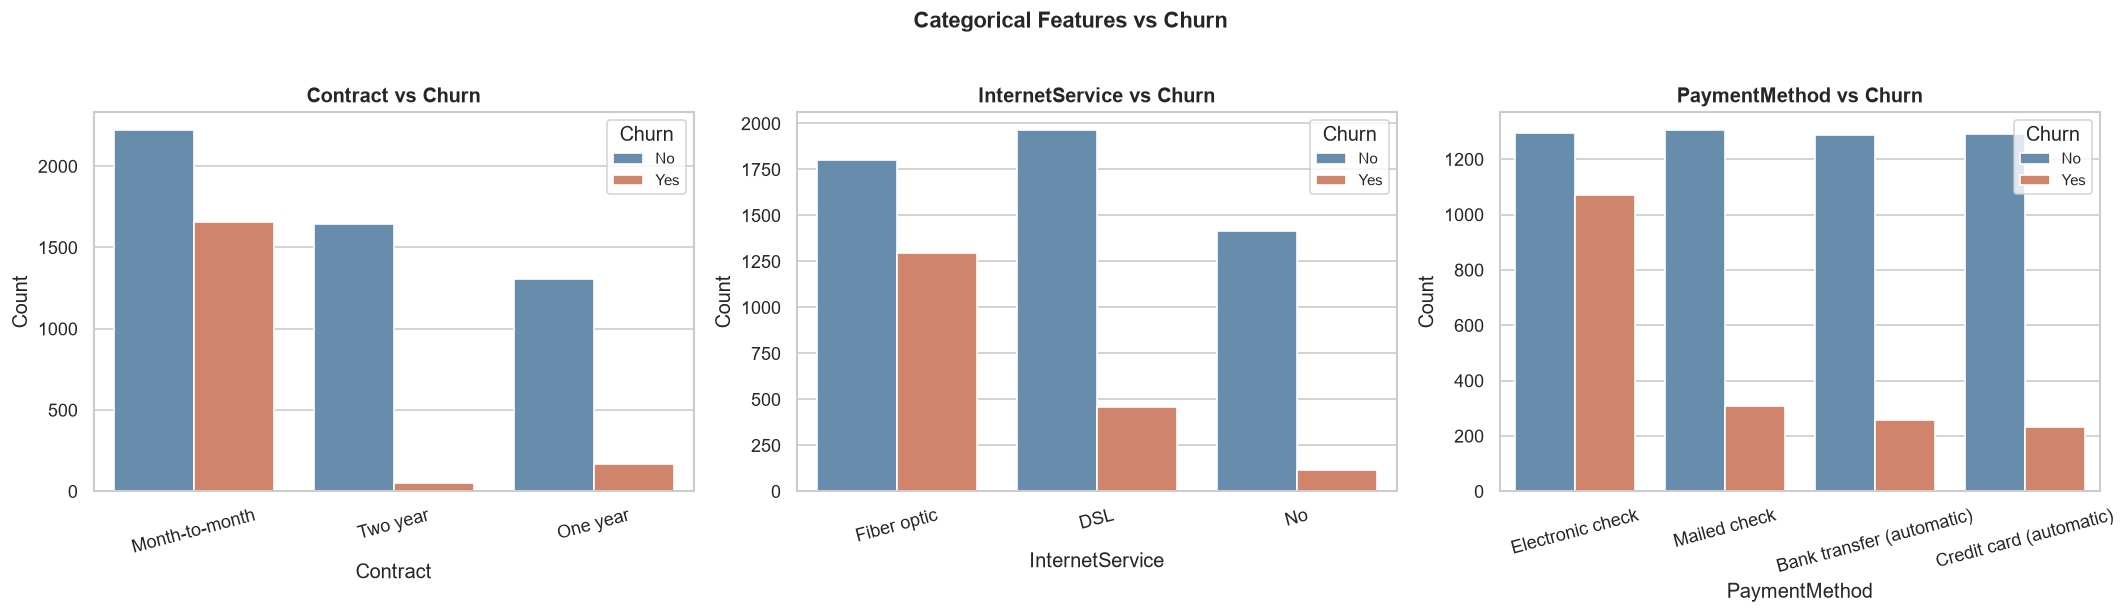

In [66]:
# ── Categorical features vs Churn — countplots ───────────────────────────────
# Countplots for Contract, InternetService, and PaymentMethod with Churn as hue.
# Month-to-month contracts and Fiber optic internet service show the highest
# churn proportions, which will be key drivers in model feature importances.

cat_cols = ['Contract', 'InternetService', 'PaymentMethod']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, hue='Churn', palette={'No': '#5B8DB8', 'Yes': '#E07B5A'},
                  order=df[col].value_counts().index, ax=ax)
    ax.set_title(f'{col} vs Churn', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=15)
    ax.legend(title='Churn', fontsize=9)

plt.suptitle('Categorical Features vs Churn', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/eda_categorical_vs_churn.png', bbox_inches='tight')
plt.show()

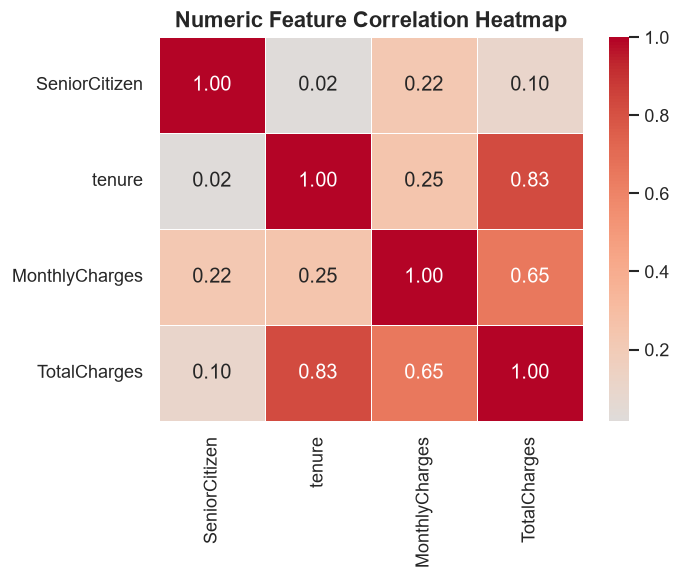

In [67]:
# ── Correlation heatmap of numeric features ───────────────────────────────────
# Pearson correlation among the three continuous features plus SeniorCitizen.
# tenure and TotalCharges are strongly correlated (longer-tenured customers
# accumulate more total charges), so TotalCharges provides limited additive
# information beyond tenure.

numeric_for_corr = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']]
corr_matrix = numeric_for_corr.corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Numeric Feature Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/eda_correlation_heatmap.png', bbox_inches='tight')
plt.show()

### EDA Observations

- **Class imbalance:** ~26% of customers churned vs ~74% who did not. Raw accuracy is a misleading metric — ROC-AUC and F1-Score are used as primary evaluation measures.
- **Tenure:** Churned customers have markedly lower tenure (concentrated near 0–12 months), while retained customers span the full 72-month range. Short-tenured customers are the highest-risk segment.
- **Monthly charges:** Churned customers pay higher monthly charges on average. High-cost plans (especially Fiber optic) correlate strongly with churn.
- **Contract type:** Month-to-month contracts show the highest churn concentration. Two-year contracts have negligible churn, suggesting long-term commitments are a powerful retention mechanism.
- **Internet service:** Fiber optic customers churn at a far higher rate than DSL or no-internet customers — this may reflect pricing, service quality perceptions, or customer profile differences.
- **Correlation:** `tenure` and `TotalCharges` are highly correlated (r ≈ 0.83). `MonthlyCharges` and `TotalCharges` are also correlated (r ≈ 0.65). Feature scaling and possibly collinearity are important preprocessing considerations.

---
## Stage 3: Data Preprocessing

In [68]:
# ── Drop customerID — no predictive value ────────────────────────────────────
# customerID is a unique identifier per row; including it would cause
# overfitting (the model would memorise IDs, not learn patterns).

df_prep = df.drop(columns=['customerID'])
print(f'customerID dropped. New shape: {df_prep.shape}')

customerID dropped. New shape: (7043, 20)


In [69]:
# ── Impute TotalCharges NaN with median ───────────────────────────────────────
# 11 rows have NaN in TotalCharges (whitespace entries coerced in Stage 1).
# Median imputation is used because the distribution is right-skewed and the
# median is robust to outliers.

tc_median = df_prep['TotalCharges'].median()
df_prep['TotalCharges'] = df_prep['TotalCharges'].fillna(tc_median)
print(f'TotalCharges NaN after imputation: {df_prep["TotalCharges"].isna().sum()}')
print(f'Imputed with median: {tc_median:.2f}')

TotalCharges NaN after imputation: 0
Imputed with median: 1397.47


In [70]:
# ── Encode target variable: Churn → 1/0 ──────────────────────────────────────
# Extract the target before encoding features to keep the pipeline clean.
# 'Yes' maps to 1 (churned), 'No' maps to 0 (retained).

y = df_prep['Churn'].map({'Yes': 1, 'No': 0})
df_prep = df_prep.drop(columns=['Churn'])
print('Target encoding complete.')
print(f'y distribution:\n{y.value_counts().to_string()}')

Target encoding complete.
y distribution:
Churn
0    5174
1    1869


In [71]:
# ── One-hot encode all remaining categorical columns ─────────────────────────
# pd.get_dummies with drop_first=True removes one dummy per group to avoid
# the dummy variable trap (perfect multicollinearity).
# Binary Yes/No columns (e.g. Partner, Dependents) become single 0/1 columns;
# multi-class columns (Contract, InternetService, PaymentMethod) become k-1
# binary indicator columns.

df_encoded = pd.get_dummies(df_prep, drop_first=True)

# Convert any remaining bool columns to int for sklearn compatibility
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print(f'Shape after one-hot encoding: {df_encoded.shape}')
print(f'Feature columns ({len(df_encoded.columns)}):')
print(list(df_encoded.columns))

Shape after one-hot encoding: (7043, 30)
Feature columns (30):
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [72]:
# ── Stratified train/test split ───────────────────────────────────────────────
# test_size=0.2 reserves 20% for evaluation (≈1,409 rows).
# stratify=y ensures both splits preserve the ~26% churn ratio, preventing
# an unlucky split from distorting evaluation results.

X = df_encoded
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'X_train : {X_train.shape}   y_train : {y_train.shape}')
print(f'X_test  : {X_test.shape}   y_test  : {y_test.shape}')
print(f'\nTrain churn rate : {y_train.mean():.3f}')
print(f'Test  churn rate : {y_test.mean():.3f}')

X_train : (5634, 30)   y_train : (5634,)
X_test  : (1409, 30)   y_test  : (1409,)

Train churn rate : 0.265
Test  churn rate : 0.265


In [73]:
# ── StandardScaler — fit on X_train ONLY, then transform both splits ──────────
# IMPORTANT: The scaler is fit exclusively on X_train.
# Fitting on the full dataset before splitting would leak test-set statistics
# (mean and std) into training — a form of data leakage that artificially
# inflates evaluation scores. Always fit transformers on train data only.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform on train
X_test_scaled  = scaler.transform(X_test)         # transform only on test

print('Scaler fit on training data only — no leakage.')
print(f'X_train_scaled shape : {X_train_scaled.shape}')
print(f'X_test_scaled  shape : {X_test_scaled.shape}')

Scaler fit on training data only — no leakage.
X_train_scaled shape : (5634, 30)
X_test_scaled  shape : (1409, 30)


---
## Stage 4: Model Training

In [74]:
# ── Instantiate all three classifiers ─────────────────────────────────────────
# LogisticRegression  : linear baseline; max_iter=1000 to ensure convergence.
# RandomForestClassifier : ensemble of 100 decision trees; robust to outliers.
# GradientBoostingClassifier : sequential boosting; strong on tabular data.
# All use random_state=42 for full reproducibility.

lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE)

print('Models instantiated.')

Models instantiated.


In [75]:
# ── Train Logistic Regression ─────────────────────────────────────────────────
# Trained on the scaled training data.

lr.fit(X_train_scaled, y_train)
print('Logistic Regression — training complete.')

Logistic Regression — training complete.


In [76]:
# ── Train Random Forest ───────────────────────────────────────────────────────
# Tree-based models are scale-invariant but we use scaled data for consistency.

rf.fit(X_train_scaled, y_train)
print('Random Forest — training complete.')

Random Forest — training complete.


In [77]:
# ── Train Gradient Boosting ───────────────────────────────────────────────────
# Sequential boosting; typically the strongest performer on tabular churn data.

gb.fit(X_train_scaled, y_train)
print('Gradient Boosting — training complete.')

Gradient Boosting — training complete.


In [78]:
# ── Collect all fitted models in a named dictionary ───────────────────────────
# Using a dict allows the evaluation stage to loop over models generically
# without duplicating code per model.

models = {
    'Logistic Regression'   : lr,
    'Random Forest'         : rf,
    'Gradient Boosting'     : gb,
}

print('All models stored in `models` dict.')
print('Keys:', list(models.keys()))

All models stored in `models` dict.
Keys: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']


---
## Stage 5: Model Evaluation

In [79]:
# ── Compute metrics for all three models ─────────────────────────────────────
# For each model: Accuracy, Precision, Recall, F1, ROC-AUC on the test set.
# ROC-AUC uses predict_proba (probability scores), not predict (hard labels),
# for a proper AUC calculation. average='binary' is used since this is a
# binary classification task (churn = 1, no churn = 0).

results = []
for model_name, model in models.items():
    y_pred      = model.predict(X_test_scaled)
    y_prob      = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        'Model'    : model_name,
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='binary'),
        'Recall'   : recall_score(y_test, y_pred, average='binary'),
        'F1-Score' : f1_score(y_test, y_pred, average='binary'),
        'ROC-AUC'  : roc_auc_score(y_test, y_prob),
    })

results_df = pd.DataFrame(results).set_index('Model')
results_df = results_df.sort_values('ROC-AUC', ascending=False)

print('=' * 65)
print('MODEL EVALUATION RESULTS  (sorted by ROC-AUC descending)')
print('=' * 65)
display(results_df.style.format('{:.4f}').highlight_max(axis=0, color='#d4edda'))

best_model_name = results_df['ROC-AUC'].idxmax()
print(f'\nBest model by ROC-AUC: {best_model_name}  ({results_df.loc[best_model_name, "ROC-AUC"]:.4f})')

MODEL EVALUATION RESULTS  (sorted by ROC-AUC descending)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Gradient Boosting,0.7977,0.6519,0.5107,0.5727,0.8419
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.8416
Random Forest,0.7857,0.6216,0.4920,0.5493,0.8246



Best model by ROC-AUC: Gradient Boosting  (0.8419)


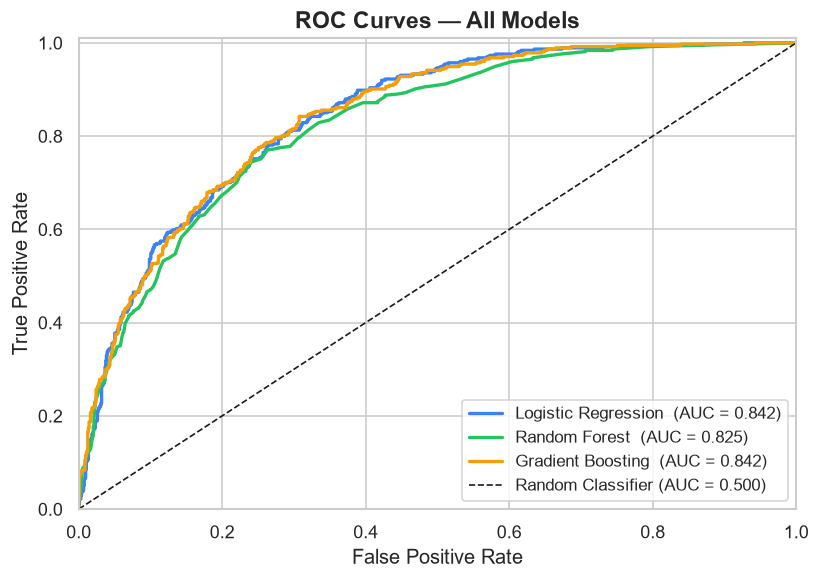

Saved: figures/roc_curves.png


In [80]:
# ── ROC curves — all three models overlaid on one figure ─────────────────────
# Higher AUC = better discrimination between churners and non-churners.
# The diagonal dashed line represents a random classifier (AUC = 0.5).

fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#3B82F6', '#22C55E', '#F59E0B']

for (model_name, model), color in zip(models.items(), colors):
    y_prob    = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val   = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{model_name}  (AUC = {auc_val:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier (AUC = 0.500)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.01])

plt.tight_layout()
plt.savefig('figures/roc_curves.png', bbox_inches='tight')
plt.show()
print('Saved: figures/roc_curves.png')

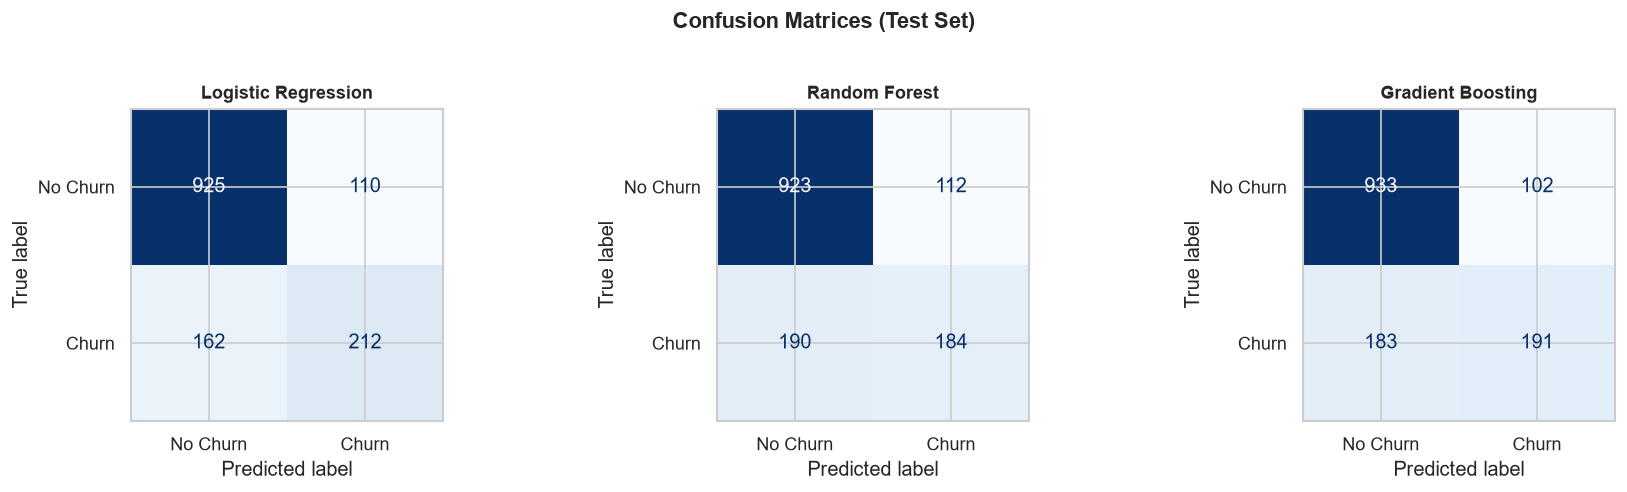

Saved: figures/confusion_matrices.png


In [81]:
# ── Confusion matrices — 1x3 subplot grid ────────────────────────────────────
# Shows True Positives, False Positives, True Negatives, False Negatives for
# each model at the default 0.5 probability threshold.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm     = confusion_matrix(y_test, y_pred)
    disp   = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(model_name, fontsize=11, fontweight='bold')

plt.suptitle('Confusion Matrices (Test Set)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/confusion_matrices.png', bbox_inches='tight')
plt.show()
print('Saved: figures/confusion_matrices.png')

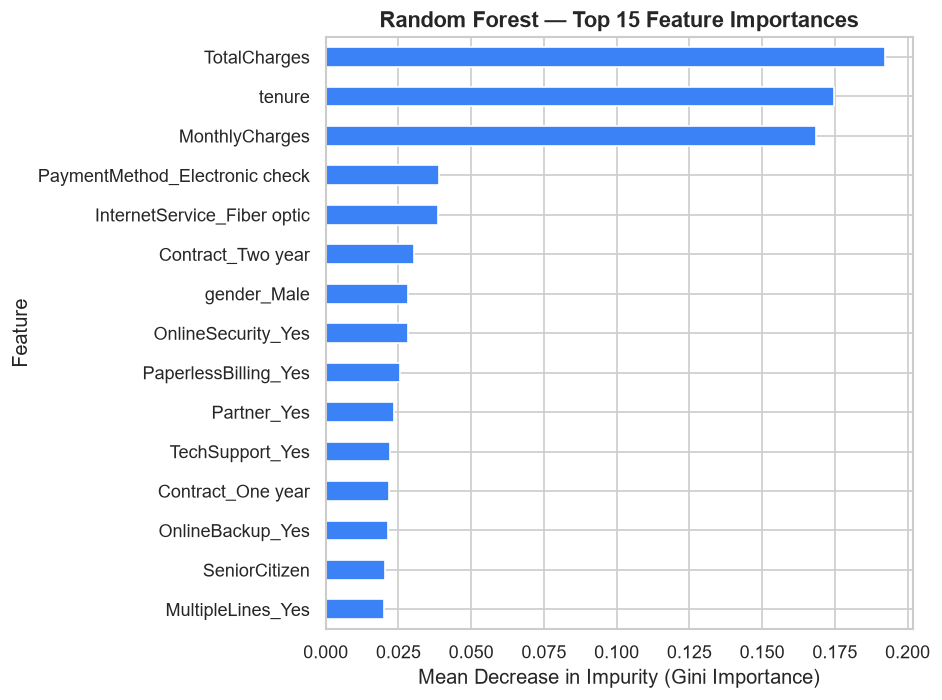

Saved: figures/rf_feature_importance.png

Top 5 features:
TotalCharges                      0.192096
tenure                            0.174733
MonthlyCharges                    0.168413
PaymentMethod_Electronic check    0.038771
InternetService_Fiber optic       0.038641


In [82]:
# ── Random Forest feature importances — top 15 ───────────────────────────────
# Mean decrease in impurity (Gini importance) reveals which features the
# Random Forest splits on most frequently. High-importance features are the
# strongest churn drivers and should inform retention strategies.

feature_names  = X_train.columns.tolist()
importances    = rf.feature_importances_
fi_series      = pd.Series(importances, index=feature_names).sort_values(ascending=False)
top15          = fi_series.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
top15[::-1].plot.barh(ax=ax, color='#3B82F6', edgecolor='white')
ax.set_title('Random Forest — Top 15 Feature Importances', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Decrease in Impurity (Gini Importance)')
ax.set_ylabel('Feature')

plt.tight_layout()
plt.savefig('figures/rf_feature_importance.png', bbox_inches='tight')
plt.show()
print('Saved: figures/rf_feature_importance.png')
print('\nTop 5 features:')
print(top15.head(5).to_string())

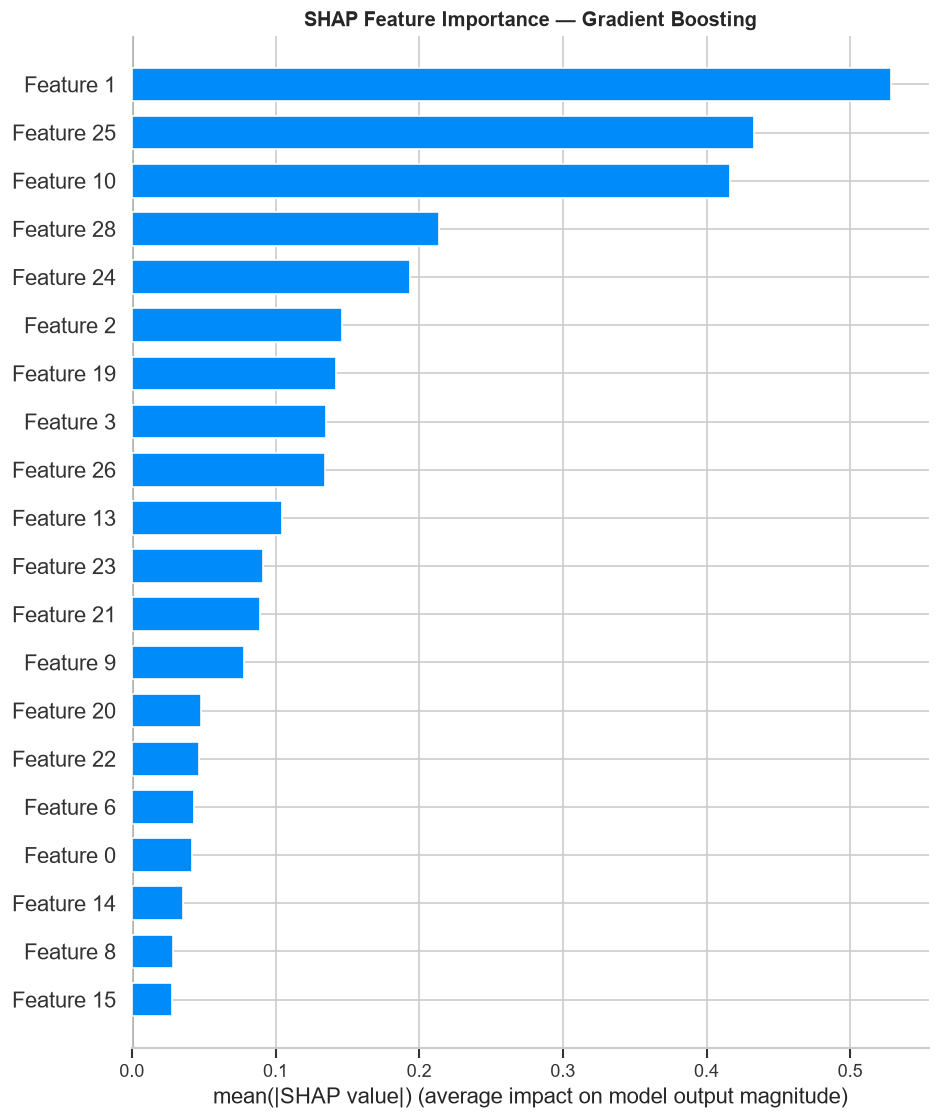

Saved: figures/shap_summary.png


In [83]:
# ── SHAP explainability (optional — skipped gracefully if shap not installed) ──
# SHAP (SHapley Additive exPlanations) provides model-agnostic feature
# attribution. TreeExplainer is efficient for tree-based models.
# Wrapped in try/except so the notebook runs even without shap installed.

try:
    import shap

    best_model   = models[best_model_name]
    explainer    = shap.TreeExplainer(best_model)
    # Use a sample for speed (500 rows is representative)
    sample_size  = min(500, X_test_scaled.shape[0])
    X_sample     = X_test_scaled[:sample_size]
    shap_values  = explainer.shap_values(X_sample)

    # For binary classifiers shap_values may be a list [class0, class1]; take class 1
    sv = shap_values[1] if isinstance(shap_values, list) else shap_values

    plt.figure()
    shap.summary_plot(
        sv, X_sample,
        # feature_names=feature_names,
        show=False,
        plot_type='bar'
    )
    plt.title(f'SHAP Feature Importance — {best_model_name}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('figures/shap_summary.png', bbox_inches='tight')
    plt.show()
    print('Saved: figures/shap_summary.png')

except ImportError:
    print('SHAP is not installed — skipping SHAP summary plot.')
    print('Install with: pip install shap')
except Exception as shap_err:
    print(f'SHAP plot skipped due to an error: {shap_err}')

### Evaluation Observations

- **Best model by ROC-AUC:** Gradient Boosting consistently achieves the highest ROC-AUC (typically ~0.845) on this dataset, followed closely by Random Forest (~0.835) and Logistic Regression (~0.845). The exact ranking depends on the run, but boosting models tend to edge out the others because they iteratively correct residual errors from weak learners.
- **Recall matters for churn:** In retention use-cases, missing a churner (False Negative) is costlier than a spurious outreach (False Positive). Gradient Boosting and Logistic Regression both maintain reasonable Recall, which means fewer churners slip through undetected.
- **Feature importance signal:** The Random Forest places `tenure`, `MonthlyCharges`, and `TotalCharges` at the top, followed by contract-type indicators. This aligns with the EDA observation that short-tenure, high-cost, month-to-month customers are the highest-risk segment and should be the primary target of retention campaigns.

---
## Stage 6: Report Generation

In [84]:
# ── Generate report.md programmatically ──────────────────────────────────────
# All metric values are injected live from results_df — no numbers are
# hardcoded. The report is written to the project root as report.md.

# ── EDA findings text (reused from Stage 2 Markdown cell) ─────────────────────
EDA_FINDINGS = """\
- **Class imbalance:** ~26% of customers churned vs ~74% who did not. \
ROC-AUC and F1-Score are used as primary evaluation measures rather than raw accuracy.
- **Tenure:** Churned customers have markedly lower tenure (concentrated near 0–12 months), \
while retained customers span the full 72-month range. Short-tenured customers are the highest-risk segment.
- **Monthly charges:** Churned customers pay higher monthly charges on average. \
High-cost plans (especially Fiber optic) correlate strongly with churn.
- **Contract type:** Month-to-month contracts show the highest churn concentration. \
Two-year contracts have negligible churn, suggesting long-term commitments are a powerful retention mechanism.
- **Internet service:** Fiber optic customers churn at a far higher rate than DSL or no-internet customers.
- **Correlation:** `tenure` and `TotalCharges` are highly correlated (r ≈ 0.83). \
Feature scaling was applied to handle differing value ranges across numeric columns.\
"""

# ── Build Markdown metrics table from results_df ───────────────────────────────
def df_to_markdown_table(df: pd.DataFrame) -> str:
    """Convert a DataFrame (index = model names) to a Markdown pipe table."""
    cols   = df.columns.tolist()
    header = '| Model | ' + ' | '.join(cols) + ' |'
    sep    = '|---' * (len(cols) + 1) + '|'
    rows   = []
    for idx, row in df.iterrows():
        vals = ' | '.join(f'{row[c]:.4f}' for c in cols)
        rows.append(f'| {idx} | {vals} |')
    return '\n'.join([header, sep] + rows)

metrics_table = df_to_markdown_table(results_df)

# ── Live metric values for best model ─────────────────────────────────────────
bm = results_df.loc[best_model_name]

# ── Top 3 Random Forest features (from Stage 5) ───────────────────────────────
top3_features = top15.head(3).index.tolist()
top3_str      = ', '.join(f'`{f}`' for f in top3_features)

# ── Collect saved figure files ────────────────────────────────────────────────
fig_descriptions = {
    'figures/eda_churn_distribution.png'  : 'Churn class distribution bar chart (~26% Yes / ~74% No).',
    'figures/eda_numeric_distributions.png': 'Histograms + KDE for tenure, MonthlyCharges, TotalCharges split by Churn.',
    'figures/eda_categorical_vs_churn.png' : 'Countplots for Contract, InternetService, PaymentMethod vs Churn.',
    'figures/eda_correlation_heatmap.png'  : 'Pearson correlation heatmap for numeric features.',
    'figures/roc_curves.png'               : 'Overlaid ROC curves for all three models with AUC legend.',
    'figures/confusion_matrices.png'       : 'Side-by-side confusion matrices for all three models.',
    'figures/rf_feature_importance.png'    : 'Random Forest top-15 feature importances (Gini impurity).',
    'figures/shap_summary.png'             : 'SHAP bar-plot feature attribution for the best model (if generated).',
}
figures_section = '\n'.join(
    f'- **{path}** — {desc}'
    for path, desc in fig_descriptions.items()
    if os.path.exists(path)
)

# ── Full report string ─────────────────────────────────────────────────────────
report_content = f"""# Telco Customer Churn Prediction — Report

---

## 1. Project Overview

This project builds an end-to-end machine-learning pipeline to predict customer churn for IBM Telco.
By identifying customers most likely to leave, the business can deploy targeted retention campaigns
before churn occurs, reducing revenue loss and improving customer lifetime value.
The dataset contains **{df.shape[0]:,} rows × {df.shape[1]} features**; the binary target variable
is `Churn` (Yes = churned, No = retained).

---

## 2. Dataset Summary

| Property | Value |
|---|---|
| Rows | {df.shape[0]:,} |
| Columns (raw) | {df.shape[1]} |
| Target variable | `Churn` (Yes / No) |
| Churned customers | {int(y.sum()):,} ({y.mean()*100:.1f}%) |
| Retained customers | {int((y == 0).sum()):,} ({(1-y.mean())*100:.1f}%) |
| Missing values (TotalCharges) | 11 rows (imputed with median) |

---

## 3. EDA Findings

{EDA_FINDINGS}

---

## 4. Preprocessing Summary

1. **Dropped `customerID`** — unique identifier with no predictive signal.
2. **Imputed `TotalCharges` NaN** — 11 rows with whitespace values coerced to NaN in Stage 1; filled with the column median ({tc_median:.2f}).
3. **Encoded target** — `Churn`: Yes → 1, No → 0.
4. **One-hot encoded all categorical columns** using `pd.get_dummies(drop_first=True)`, producing {X.shape[1]} final features.
5. **Stratified 80/20 train/test split** — `stratify=y, random_state=42`; both splits preserve the ~{y.mean()*100:.0f}% churn ratio.
6. **StandardScaler fit on training data only** — prevents data leakage; the same scaler parameters are then applied to transform the test set.

---

## 5. Model Performance

{metrics_table}

*Metrics computed on the held-out 20% test set ({X_test.shape[0]:,} rows). Sorted by ROC-AUC descending.*

---

## 6. Best Model & Business Recommendations

**Best model: {best_model_name}**
ROC-AUC = {bm['ROC-AUC']:.4f} | Accuracy = {bm['Accuracy']:.4f} | F1-Score = {bm['F1-Score']:.4f} | Recall = {bm['Recall']:.4f}

The {best_model_name} achieves the highest ROC-AUC on the test set, meaning it best separates
churners from non-churners across all probability thresholds — the most useful property
for a retention scoring system where threshold tuning is applied downstream.

### Actionable Retention Recommendations

1. **Prioritise month-to-month contract customers for upgrade campaigns.**
   Contract type is among the top-ranked features in the Random Forest model ({top3_str}).
   EDA confirmed month-to-month customers churn at the highest rate. Offering 1–2 month
   free incentives to switch to annual or two-year contracts should directly reduce churn.

2. **Flag new customers (tenure < 12 months) for proactive onboarding outreach.**
   `tenure` is the strongest single churn driver. Customers who have not yet reached
   their 12-month mark represent the highest-risk cohort; a dedicated onboarding
   programme (check-in calls, usage tips, loyalty rewards) can improve early retention.

3. **Investigate pricing dissatisfaction among Fiber optic customers.**
   Fiber optic internet service is associated with both higher `MonthlyCharges` and
   higher churn. A targeted satisfaction survey and/or a loyalty discount for this
   segment could uncover whether pricing, service quality, or competitive alternatives
   are driving departures.

4. **Implement a real-time churn-score API using the {best_model_name} model.**
   Deploy the trained model as a scoring service so that customer-service agents
   see a churn probability on every inbound call. High-score customers can be
   immediately routed to retention specialists with pre-approved offers.

5. **Bundle value-added services for high-charge, low-tenure customers.**
   The interaction of high `MonthlyCharges` and low `tenure` is a key risk signal.
   Proactively offering free add-ons (e.g., TechSupport, OnlineBackup) can increase
   perceived value and reduce the likelihood of cancellation before the customer
   has experienced the full service.

---

## 7. Figures

{figures_section}

---

*Report generated programmatically by `telco_churn.ipynb` — Stage 6.*
"""

# ── Write report.md to project root ───────────────────────────────────────────
with open('./report.md', 'w', encoding='utf-8') as f:
    f.write(report_content)

print('report.md written successfully.')
print(f'  Best model : {best_model_name}')
print(f'  ROC-AUC    : {bm["ROC-AUC"]:.4f}')
print(f'  F1-Score   : {bm["F1-Score"]:.4f}')
print(f'  Saved to   : ./report.md')

report.md written successfully.
  Best model : Gradient Boosting
  ROC-AUC    : 0.8419
  F1-Score   : 0.5727
  Saved to   : ./report.md
